# Rolling features

Turn raw sensor readings into features that describe the recent trend: for each sensor, the mean, standard deviation, and slope over the last 10 cycles of the same engine.

In [1]:
import sys
sys.path.append("../src")
import matplotlib.pyplot as plt
from load_data import load_test, load_train
from features import FEATURES, WINDOW, add_rolling_features

## 1. Build

Compute the rolling features for the entire training set. We verify the resulting dataframe dimensions, the 57 total feature names, and ensure zero missing values are present.

In [2]:
train = add_rolling_features(load_train())

print(f"train.shape: {train.shape}")
print(f"len(FEATURES): {len(FEATURES)}")
print(f"First 6 FEATURES: {FEATURES[:6]}")
print(f"Last 3 FEATURES: {FEATURES[-3:]}")
print(f"NaN in train[FEATURES]: {train[FEATURES].isna().sum().sum()}")

train.shape: (20631, 69)
len(FEATURES): 57
First 6 FEATURES: ['cycle', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8']
Last 3 FEATURES: ['sensor_21_mean', 'sensor_21_std', 'sensor_21_slope']
NaN in train[FEATURES]: 0


## 2. Look at the numbers

Inspect sensor 2 for engine 1 across cycles 1 to 12 alongside its rolling mean, std, and slope. The mean smooths noise, the std reflects local fluctuation, and the slope quantifies drift.

In [3]:
cols = ["cycle", "sensor_2", "sensor_2_mean", "sensor_2_std", "sensor_2_slope"]
e1_early = train.query("engine_id == 1 and 1 <= cycle <= 12")[cols]
e1_early

,cycle,sensor_2,sensor_2_mean,sensor_2_std,sensor_2_slope
0,1,641.82,641.820000,0.000000,0.000000
1,2,642.15,641.985000,0.233345,0.330000
2,3,642.35,642.106667,0.267644,0.265000
3,4,642.35,642.167500,0.250117,0.179000
4,5,642.37,642.208000,0.234776,0.130000
5,6,642.10,642.190000,0.214569,0.058857
6,7,642.48,642.231429,0.224457,0.067857
7,8,642.56,642.272500,0.238073,0.072619
8,9,642.12,642.255556,0.228425,0.040667
9,10,641.71,642.201000,0.275941,-0.000182


## 3. Plot

A two-panel plot for engine 1 over its entire lifetime. The upper panel displays raw sensor 11 readings against the 10-cycle rolling mean, and the lower panel shows the rolling slope (wear signal).

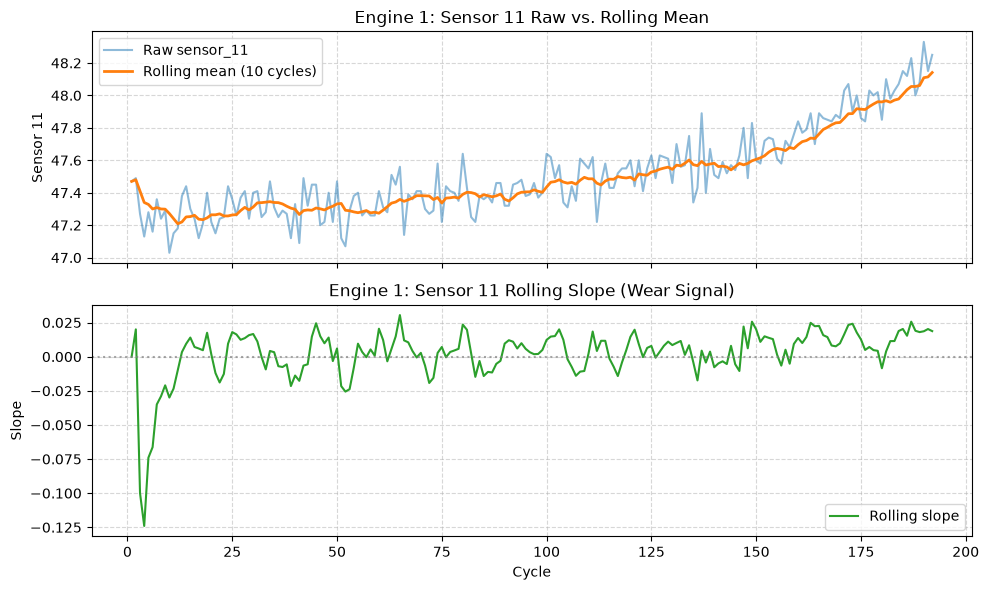

In [4]:
e1 = train[train["engine_id"] == 1]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax1.plot(e1["cycle"], e1["sensor_11"], label="Raw sensor_11", alpha=0.5, color="tab:blue")
ax1.plot(e1["cycle"], e1["sensor_11_mean"], label="Rolling mean (10 cycles)", color="tab:orange", linewidth=2)
ax1.set_ylabel("Sensor 11")
ax1.set_title("Engine 1: Sensor 11 Raw vs. Rolling Mean")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.plot(e1["cycle"], e1["sensor_11_slope"], label="Rolling slope", color="tab:green", linewidth=1.5)
ax2.axhline(0, color="gray", linestyle=":", alpha=0.7)
ax2.set_xlabel("Cycle")
ax2.set_ylabel("Slope")
ax2.set_title("Engine 1: Sensor 11 Rolling Slope (Wear Signal)")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 4. The window stays inside one engine

Check engine 2 at cycle 1 to verify that no data leaked from engine 1's final cycles. The rolling mean matches the raw sensor value, and both std and slope evaluate to 0.

In [5]:
e2_c1 = train.query("engine_id == 2 and cycle == 1")[cols]
print(e2_c1.to_string(index=False))

row = e2_c1.iloc[0]
print(f"\nMean equals raw reading: {row['sensor_2_mean'] == row['sensor_2']}")
print(f"Std is 0.0: {row['sensor_2_std'] == 0.0}")
print(f"Slope is 0.0: {row['sensor_2_slope'] == 0.0}")

 cycle  sensor_2  sensor_2_mean  sensor_2_std  sensor_2_slope
     1    641.89         641.89           0.0             0.0

Mean equals raw reading: True
Std is 0.0: True
Slope is 0.0: True


## 5. Features use only the past

Compute rolling features on engine 1 truncated at cycle 100 and compare against cycle 100 in the full table. Because test engines are cut off before failure, feature extraction must never look forward in time.

In [6]:
cut = add_rolling_features(load_train().query("engine_id == 1 and cycle <= 100"))
last_cut_row = cut[FEATURES].iloc[-1]
full_100_row = train.query("engine_id == 1 and cycle == 100")[FEATURES].iloc[0]

print("Last row of cut equals full-table row:", last_cut_row.equals(full_100_row))

Last row of cut equals full-table row: True


## 6. Which features relate to RUL

Determine the 10 features with the highest absolute linear correlation with RUL. Smoothed rolling means capture degraded engine states more strongly than individual noisy raw measurements.

In [7]:
top_corr = (
    train[FEATURES]
    .corrwith(train["rul"])
    .abs()
    .sort_values(ascending=False)
    .head(10)
)
print(top_corr)

cycle             0.736241
sensor_4_mean     0.732868
sensor_21_mean    0.729701
sensor_11_mean    0.728727
sensor_17_mean    0.728268
sensor_15_mean    0.727228
sensor_3_mean     0.726007
sensor_20_mean    0.723255
sensor_2_mean     0.721540
sensor_7_mean     0.711189
dtype: float64


## 7. Test file works too

Apply the rolling feature transformation to the test dataset. We verify that the test set processes successfully and yields the expected 68 columns.

In [8]:
test = add_rolling_features(load_test())
print(f"test.shape: {test.shape}")

test.shape: (13096, 68)
